In [50]:
import pandas as pd
print("Pandas version :",pd.__version__)

Pandas version : 3.0.6


In [51]:
import pandas as pd

file_path = "../data/paysim.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [52]:
df.shape


(6362620, 11)

In [53]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [54]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB

Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [55]:
# Count transactions in each fraud-label category
fraud_counts = df["isFraud"].value_counts().sort_index()

print("Transaction counts by fraud label:")
print(fraud_counts)

# Calculate the percentage of all transactions
fraud_percentage = df["isFraud"].value_counts(normalize=True).sort_index() * 100

print("\nTransaction percentages:")
print(fraud_percentage.round(4))


Transaction counts by fraud label:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Transaction percentages:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


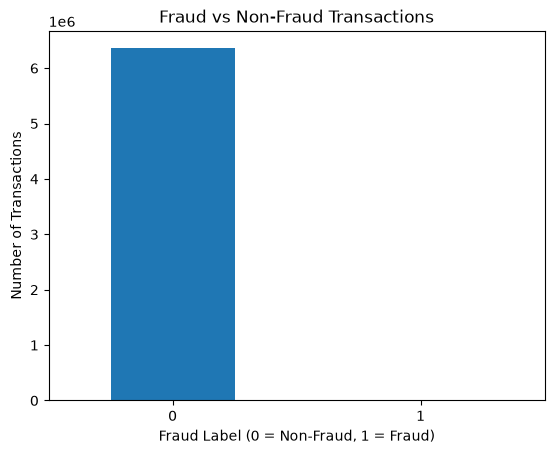

In [56]:
import matplotlib.pyplot as plt

fraud_counts.plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud Label (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [57]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [58]:
import matplotlib.pyplot as plt

print("Matplotlib is ready!")

Matplotlib is ready!


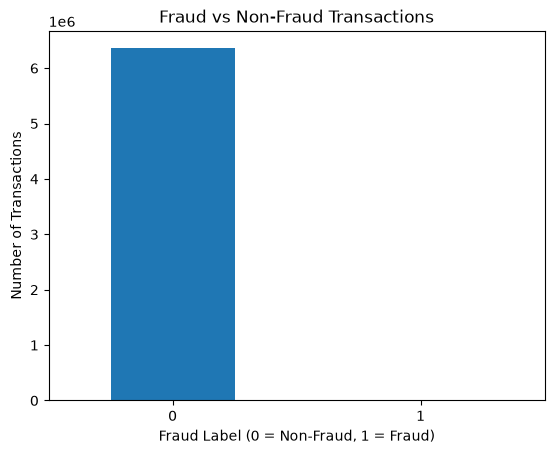

In [59]:
fraud_counts.plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud Label (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [60]:
fraud_by_type = df.groupby("type")["isFraud"].agg(
    total_transactions="count",
    fraud_cases="sum"
)

fraud_by_type["fraud_rate_pct"] = (
    fraud_by_type["fraud_cases"]
    / fraud_by_type["total_transactions"]
    * 100
)

print(fraud_by_type.sort_values("fraud_rate_pct", ascending=False))

          total_transactions  fraud_cases  fraud_rate_pct
type                                                     
TRANSFER              532909         4097        0.768799
CASH_OUT             2237500         4116        0.183955
CASH_IN              1399284            0        0.000000
DEBIT                  41432            0        0.000000
PAYMENT              2151495            0        0.000000


In [61]:
df[df["isFraud"] == 1]["type"].value_counts()

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

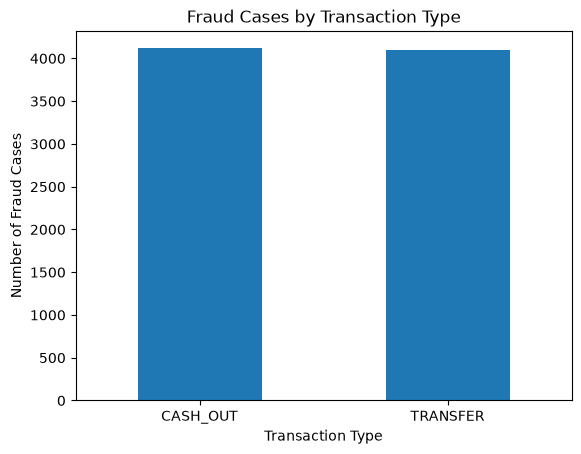

In [62]:
fraud_counts = df[df["isFraud"] == 1]["type"].value_counts()

fraud_counts.plot(kind="bar", title="Fraud Cases by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Cases")
plt.xticks(rotation=0)
plt.show()

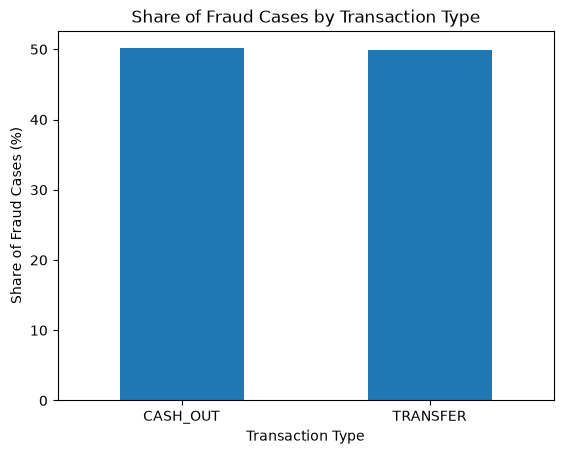

In [63]:
fraud_counts = df[df["isFraud"] == 1]["type"].value_counts()

fraud_percentages = fraud_counts / fraud_counts.sum() * 100

fraud_percentages.plot(
    kind="bar",
    title="Share of Fraud Cases by Transaction Type"
)

plt.xlabel("Transaction Type")
plt.ylabel("Share of Fraud Cases (%)")
plt.xticks(rotation=0)
plt.show()

In [64]:
df["expected_newbalanceOrig"] = (
    df["oldbalanceOrg"] - df["amount"]
)

df[[
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "expected_newbalanceOrig"
]].head()

,type,amount,oldbalanceOrg,newbalanceOrig,expected_newbalanceOrig
0,PAYMENT,9839.64,170136.0,160296.36,160296.36
1,PAYMENT,1864.28,21249.0,19384.72,19384.72
2,TRANSFER,181.00,181.0,0.00,0.00
3,CASH_OUT,181.00,181.0,0.00,0.00
4,PAYMENT,11668.14,41554.0,29885.86,29885.86


In [65]:
df["balance_difference"] = (
    df["newbalanceOrig"] - df["expected_newbalanceOrig"]
)

df[[
    "type",
    "amount",
    "newbalanceOrig",
    "expected_newbalanceOrig",
    "balance_difference"
]].head()

,type,amount,newbalanceOrig,expected_newbalanceOrig,balance_difference
0,PAYMENT,9839.64,160296.36,160296.36,0.0
1,PAYMENT,1864.28,19384.72,19384.72,0.0
2,TRANSFER,181.00,0.00,0.00,0.0
3,CASH_OUT,181.00,0.00,0.00,0.0
4,PAYMENT,11668.14,29885.86,29885.86,0.0


In [66]:
(df["balance_difference"] != 0).sum()

np.int64(5413997)

In [67]:
def count_nonzero(balance_difference):
    return (balance_difference != 0).sum()

df.groupby("type")["balance_difference"].apply(count_nonzero)

type
CASH_IN     1399284
CASH_OUT    2079096
DEBIT         15881
PAYMENT     1402519
TRANSFER     517217
Name: balance_difference, dtype: int64

In [68]:
df["balance_difference"].abs().describe()

count    6.362620e+06
mean     2.010925e+05
std      6.066505e+05
min      0.000000e+00
25%      2.954230e+03
50%      6.867726e+04
75%      2.496411e+05
max      9.244552e+07
Name: balance_difference, dtype: float64

In [69]:
df[df["isFraud"] == 1][[
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "balance_difference"
]].head(10)

,type,amount,oldbalanceOrg,newbalanceOrig,balance_difference
2,TRANSFER,181.00,181.00,0.0,0.00
3,CASH_OUT,181.00,181.00,0.0,0.00
251,TRANSFER,2806.00,2806.00,0.0,0.00
252,CASH_OUT,2806.00,2806.00,0.0,0.00
680,TRANSFER,20128.00,20128.00,0.0,0.00
681,CASH_OUT,20128.00,20128.00,0.0,0.00
724,CASH_OUT,416001.33,0.00,0.0,416001.33
969,TRANSFER,1277212.77,1277212.77,0.0,0.00
970,CASH_OUT,1277212.77,1277212.77,0.0,0.00
1115,TRANSFER,35063.63,35063.63,0.0,0.00


In [70]:
fraud_balance_mismatch = df[
    (df["isFraud"] == 1) &
    (df["balance_difference"] != 0)
]

print("Fraud cases with non-zero balance difference:",
      len(fraud_balance_mismatch))

Fraud cases with non-zero balance difference: 127


In [71]:
fraud_balance_mismatch["type"].value_counts()

type
TRANSFER    103
CASH_OUT     24
Name: count, dtype: int64

In [72]:
# Count mismatched fraud cases by type
mismatch_counts = fraud_balance_mismatch["type"].value_counts()

# Count all fraud-labelled cases by type
total_fraud_counts = df[df["isFraud"] == 1]["type"].value_counts()

# Calculate mismatch percentages
mismatch_percentages = (
    mismatch_counts / total_fraud_counts * 100
).round(2)

print(mismatch_percentages)

type
CASH_OUT    0.58
TRANSFER    2.51
Name: count, dtype: float64


### Fraud Balance Mismatch Analysis

- Total fraud-labelled transactions: 8,213
- Fraud-labelled transactions with non-zero balance differences: 127
- TRANSFER mismatch cases: 103
- CASH_OUT mismatch cases: 24
- TRANSFER mismatch percentage among fraud-labelled transfers: 2.51%
- CASH_OUT mismatch percentage among fraud-labelled cash-outs: 0.58%

**Key finding:** TRANSFER transactions had a higher percentage of non-zero origin-balance differences than CASH_OUT transactions among fraud-labelled cases. However, a balance mismatch alone does not prove fraud. This check should be used as an investigation indicator, not as a standalone fraud detector.

In [73]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


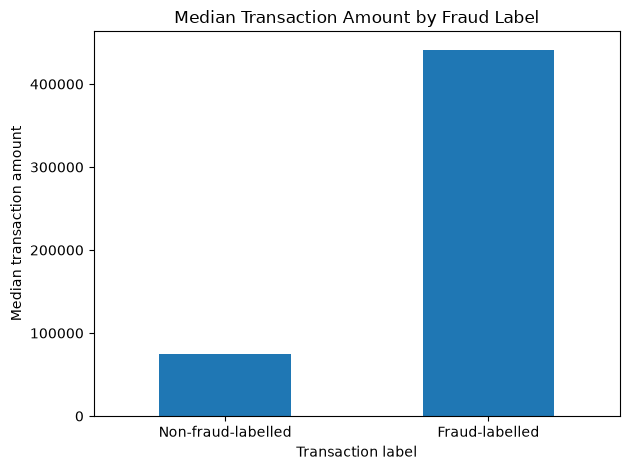

In [74]:
import matplotlib.pyplot as plt

median_amounts = df.groupby("isFraud")["amount"].median()

median_amounts.index = ["Non-fraud-labelled", "Fraud-labelled"]

median_amounts.plot(kind="bar")

plt.title("Median Transaction Amount by Fraud Label")
plt.xlabel("Transaction label")
plt.ylabel("Median transaction amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
df[df["isFraud"] == 1].groupby("type")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
CASH_OUT,4116.0,1.455103e+06,2.393842e+06,0.0,125464.45,435516.905,1500761.03,10000000.0
TRANSFER,4097.0,1.480892e+06,2.414890e+06,63.8,128417.96,445705.760,1534985.07,10000000.0


### Fraud-Labelled Transaction Amounts by Type

The PaySim dataset contains 4,116 fraud-labelled CASH_OUT transactions and 4,097 fraud-labelled TRANSFER transactions.

TRANSFER transactions had a median amount of approximately 445,705.76, compared with 435,516.91 for CASH_OUT. Their mean amounts were approximately 1.48 million and 1.46 million, respectively. Both types had a maximum transaction amount of 10 million.

**Key finding:** Fraud-labelled TRANSFER transactions had slightly higher average and median amounts than fraud-labelled CASH_OUT transactions. However, the distributions overlap substantially, so transaction amount alone is insufficient to identify fraud.

In [76]:
fraud_df = df[df["isFraud"] == 1]

print("Fraud-labelled transactions:", len(fraud_df))

print(
    "Origin balance was zero before transaction:",
    (fraud_df["oldbalanceOrg"] == 0).sum()
)

print(
    "Origin balance was zero after transaction:",
    (fraud_df["newbalanceOrig"] == 0).sum()
)

Fraud-labelled transactions: 8213
Origin balance was zero before transaction: 41
Origin balance was zero after transaction: 8053


In [77]:
def count_zero_balances(balance):
    return (balance == 0).sum()

df.groupby("isFraud")["newbalanceOrig"].apply(count_zero_balances)

isFraud
0    3601513
1       8053
Name: newbalanceOrig, dtype: int64

In [78]:
def zero_balance_percentage(balance):
    return (balance == 0).mean() * 100

df.groupby("isFraud")["newbalanceOrig"].apply(
    zero_balance_percentage
).round(2)

isFraud
0    56.68
1    98.05
Name: newbalanceOrig, dtype: float64

### Zero Ending Origin Balance Analysis

The analysis found that 98.05% of fraud-labelled transactions had a zero ending origin balance, compared with 56.68% of non-fraud-labelled transactions—a difference of approximately 41.37 percentage points.

**Key finding:** A zero ending origin balance was substantially more common among fraud-labelled transactions in the PaySim dataset. However, it was also common among non-fraud-labelled transactions, so this feature should be combined with other indicators rather than used alone to identify fraud.

In [79]:
fraud_df.groupby(
    fraud_df["newbalanceOrig"] == 0
)["amount"].median()

newbalanceOrig
False    10000000.00
True       422261.63
Name: amount, dtype: float64

In [80]:
fraud_df.groupby(
    fraud_df["newbalanceOrig"] == 0
)["amount"].count()

newbalanceOrig
False     160
True     8053
Name: amount, dtype: int64

In [81]:
fraud_df[fraud_df["newbalanceOrig"] != 0]["amount"].describe()

count    1.600000e+02
mean     9.367638e+06
std      2.142959e+06
min      4.206282e+04
25%      1.000000e+07
50%      1.000000e+07
75%      1.000000e+07
max      1.000000e+07
Name: amount, dtype: float64

In [82]:
(fraud_df["amount"] == 10_000_000).sum()

np.int64(287)

In [83]:
fraud_at_limit = (fraud_df["amount"] == 10_000_000).sum()

fraud_at_limit_pct = (
    fraud_at_limit / len(fraud_df) * 100
)

print("Fraud-labelled transactions at 10 million:", fraud_at_limit)
print("Percentage of fraud-labelled transactions:", round(fraud_at_limit_pct, 2), "%")


Fraud-labelled transactions at 10 million: 287
Percentage of fraud-labelled transactions: 3.49 %


### High-Value Fraud-Labelled Transactions

Among the 8,213 fraud-labelled transactions in the PaySim dataset, 287 transactions had an amount of exactly 10,000,000, representing approximately 3.49% of the fraud-labelled group.

A separate analysis of fraud-labelled transactions with non-zero ending origin balances found a strong concentration at this amount: the 25th percentile, median, 75th percentile, and maximum were all 10,000,000.

**Key finding:** Some fraud-labelled transactions were concentrated at the 10-million amount level. Further comparison with non-fraud-labelled transactions is needed to determine how distinctive this pattern is. Transaction amount alone does not establish fraud.

In [84]:
def count_transactions_at_limit(amount):
    return (amount == 10_000_000).sum()

df.groupby("isFraud")["amount"].apply(
    count_transactions_at_limit
)

isFraud
0    2920
1     287
Name: amount, dtype: int64

In [85]:
limit_counts = df.groupby("isFraud")["amount"].apply(
    count_transactions_at_limit
)

group_counts = df["isFraud"].value_counts().sort_index()

limit_percentages = (
    limit_counts / group_counts * 100
).round(2)

print(limit_percentages)

isFraud
0    0.05
1    3.49
dtype: float64


### High-Value Transaction Analysis

Among 8,213 fraud-labelled transactions, 287 had an amount of exactly 10,000,000, representing 3.49% of the fraud-labelled group. Among non-fraud-labelled transactions, 2,920 had this amount, representing approximately 0.05% of that much larger group.

**Key finding:** Transactions at the 10-million amount level were approximately 70 times more common proportionally among fraud-labelled transactions than among non-fraud-labelled transactions. This suggests that transaction amount may be a useful risk-analysis feature in this dataset. However, amount alone cannot establish fraud, and the pattern should be validated against other transaction characteristics.


In [86]:
df.groupby("type")["amount"].median().sort_values(ascending=False)

type
TRANSFER    486308.390
CASH_OUT    147072.185
CASH_IN     143427.710
PAYMENT       9482.190
DEBIT         3048.990
Name: amount, dtype: float64

### Median Transaction Amount by Type

The median transaction amount varies considerably across transaction types. TRANSFER has the highest median amount (486,308.39), followed by CASH_OUT (147,072.19) and CASH_IN (143,427.71). PAYMENT (9,482.19) and DEBIT (3,048.99) have substantially lower median amounts.

**Key finding:** TRANSFER transactions have a considerably higher typical transaction amount than the other transaction types. Transaction type and amount may therefore be useful features for identifying transactions that deserve further risk analysis. However, a high amount alone does not establish fraud.

In [87]:
df.groupby(["type", "isFraud"])["amount"].mean().round(2)

type      isFraud
CASH_IN   0           168920.24
CASH_OUT  0           173917.16
          1          1455102.59
DEBIT     0             5483.67
PAYMENT   0            13057.60
TRANSFER  0           906229.01
          1          1480891.67
Name: amount, dtype: float64

### Average Transaction Amount by Fraud Label and Type

The average transaction amount differs substantially between fraud-labelled and non-fraud-labelled transactions in the CASH_OUT and TRANSFER categories. Fraud-labelled CASH_OUT transactions averaged 1,455,102.59, compared with 173,917.16 for non-fraud-labelled CASH_OUT transactions. Fraud-labelled TRANSFER transactions averaged 1,480,891.67, compared with 906,229.01 for non-fraud-labelled transfers.

No fraud-labelled transactions were present in the CASH_IN, DEBIT, or PAYMENT categories in this dataset.

**Key finding:** Transaction amount may help distinguish fraud-labelled activity within CASH_OUT and TRANSFER transactions. However, averages can be influenced by extreme values, and these patterns in the synthetic PaySim dataset do not prove that transaction amount alone can identify fraud.

In [88]:
fraud_rate_by_type = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate_by_type.round(3).sort_values(ascending=False))

type
TRANSFER    0.769
CASH_OUT    0.184
CASH_IN     0.000
DEBIT       0.000
PAYMENT     0.000
Name: isFraud, dtype: float64


### Fraud Rate by Transaction Type

TRANSFER had the highest fraud-labelled transaction rate at approximately 0.769%, followed by CASH_OUT at approximately 0.184%. CASH_IN, DEBIT, and PAYMENT had no fraud-labelled transactions in this dataset.

**Key finding:** TRANSFER had a fraud-labelled rate approximately 4.2 times that of CASH_OUT. This suggests that transaction type may be useful for prioritising further risk analysis. However, the zero rates in other categories reflect this dataset and should not be interpreted as proof that these transaction types are always safe.

In [89]:
df.groupby("isFraud")["amount"].median().round(2)

isFraud
0     74684.72
1    441423.44
Name: amount, dtype: float64

In [90]:
df["step"].value_counts().sort_index()

step
1      2708
2      1014
3       552
4       565
5       665
       ... 
739      10
740       6
741      22
742      14
743       8
Name: count, Length: 743, dtype: int64

In [91]:
transactions_per_step = df["step"].value_counts()

print("Busiest time step:")
print(transactions_per_step.idxmax(),
      transactions_per_step.max())

print("Quietest time step:")
print(transactions_per_step.idxmin(),
      transactions_per_step.min())

Busiest time step:
19 51352
Quietest time step:
112 2


In [92]:
fraud_per_step = df.groupby("step")["isFraud"].sum()

print("Time step with most fraud-labelled transactions:")
print(fraud_per_step.idxmax(), fraud_per_step.max())

Time step with most fraud-labelled transactions:
212 40


In [93]:
fraud_rate_per_step = df.groupby("step")["isFraud"].mean() * 100

print("Time step with highest fraud rate:")
print(
    fraud_rate_per_step.idxmax(),
    round(fraud_rate_per_step.max(), 3),
    "%"
)

Time step with highest fraud rate:
28 100.0 %


In [94]:
step_28 = df[df["step"] == 28]

print("Total transactions:", len(step_28))
print("Fraud-labelled transactions:", step_28["isFraud"].sum())
print("Fraud rate:",
      round(step_28["isFraud"].mean() * 100, 2), "%")

Total transactions: 4
Fraud-labelled transactions: 4
Fraud rate: 100.0 %


In [95]:
fraud_per_step = df.groupby("step")["isFraud"].sum()

print(fraud_per_step.sort_values(ascending=False).head(5))

step
212    40
523    30
249    28
425    28
501    28
Name: isFraud, dtype: int64


### Fraud Activity Over Time

The highest number of fraud-labelled transactions occurred at step 212, with 40 cases. The next highest counts were step 523 (30 cases), step 249 (28 cases), step 425 (28 cases), and step 501 (28 cases).

The time step with the highest observed fraud rate was step 28, where all four transactions were fraud-labelled. However, this rate was based on a very small transaction volume.

**Key finding:** Fraud-labelled transaction counts and fraud rates vary across simulation time steps. Both measures should be interpreted alongside total transaction volume to avoid drawing misleading conclusions from small samples. These observations describe the synthetic PaySim dataset and should not be assumed to represent real-world fraud patterns.


In [96]:
transaction_type_counts = df["type"].value_counts()

print(transaction_type_counts)

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


### Transaction Volume by Type

CASH_OUT was the most common transaction type, with 2,237,500 transactions (approximately 35.17% of the dataset), followed by PAYMENT with 2,151,495 transactions (approximately 33.81%). CASH_IN accounted for approximately 22.00%, TRANSFER for 8.38%, and DEBIT for 0.65%.

**Key finding:** CASH_OUT and PAYMENT together represented approximately 69% of all transactions. However, TRANSFER had the highest fraud-labelled rate despite accounting for a much smaller share of total volume. This demonstrates why transaction volume should be analysed alongside fraud rates when prioritising risk analysis.

In [97]:
df.duplicated().sum()

np.int64(0)

### Duplicate Row Check

The dataset contains 6,362,620 rows, and the duplicate-row check returned zero exact duplicates across all columns.

**Key finding:** No exact duplicate rows were identified. Combined with the earlier missing-value check, this suggests that the dataset is structurally complete for the initial exploratory analysis. However, the check does not rule out transaction-level anomalies or duplicates based on selected business keys.

In [98]:

import pandas as pd
import sqlite3

csv_path = "data/paysim.csv"
db_path = "data/fraud_analysis.db"
table_name = "transactions"

batch_size = 100_000

with sqlite3.connect(db_path) as conn:
    first_batch = True

    for chunk in pd.read_csv(csv_path, chunksize=batch_size):
        chunk.to_sql(
            table_name,
            conn,
            if_exists="replace" if first_batch else "append",
            index=False
        )

        first_batch = False
        print(f"Loaded {len(chunk):,} rows")

print("Data loading completed successfully!")


OperationalError: unable to open database file

In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nDoes the database path exist?")
print(os.path.exists("data/fraud_analysis.db"))

print("\nDoes the CSV path exist?")
print(os.path.exists("data/paysim.csv"))

Current working directory:
c:\Users\jishn\python-projects\transaction-fraud-analysis\notebooks

Does the database path exist?
False

Does the CSV path exist?
False


In [ ]:
csv_path = "data/paysim.csv"
db_path = "data/fraud_analysis.db"

In [ ]:
import os

print("CSV exists:", os.path.exists("../data/paysim.csv"))
print("Database folder exists:", os.path.isdir("../data"))
print("Database file exists:", os.path.exists("../data/fraud_analysis.db"))

In [ ]:
import os

print("CSV exists:", os.path.exists("../data/paysim.csv"))
print("Database folder exists:", os.path.isdir("../data"))
print("Database file exists:", os.path.exists("../data/fraud_analysis.db"))

CSV exists: True
Database folder exists: True
Database file exists: True


In [ ]:

import pandas as pd
import sqlite3

csv_path = "../data/paysim.csv"
db_path = "../data/fraud_analysis.db"
table_name = "transactions"

batch_size = 100_000

with sqlite3.connect(db_path) as conn:
    first_batch = True

    for chunk in pd.read_csv(csv_path, chunksize=batch_size):
        chunk.to_sql(
            table_name,
            conn,
            if_exists="replace" if first_batch else "append",
            index=False
        )

        first_batch = False
        print(f"Loaded {len(chunk):,} rows")

print("Data loading completed successfully!")


Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows
Loaded 100,000 rows


In [ ]:

import sqlite3

db_path = "../data/fraud_analysis.db"

with sqlite3.connect(db_path) as conn:
    cursor = conn.cursor()

    cursor.execute("SELECT COUNT(*) FROM transactions")
    total_rows = cursor.fetchone()[0]

    cursor.execute("PRAGMA table_info(transactions)")
    columns = cursor.fetchall()

print("Total rows in SQLite:", f"{total_rows:,}")
print("\nColumns in the transactions table:")

for column in columns:
    print(column[1])


Total rows in SQLite: 6,362,620

Columns in the transactions table:
step
type
amount
nameOrig
oldbalanceOrg
newbalanceOrig
nameDest
oldbalanceDest
newbalanceDest
isFraud
isFlaggedFraud


In [ ]:
import sqlite3

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()

    cursor.execute("""
        SELECT
            type,
            COUNT(*) AS total_transactions
        FROM transactions
        GROUP BY type
        ORDER BY total_transactions DESC;
    """)

    results = cursor.fetchall()

for row in results:
    print(row)

('CASH_OUT', 2237500)
('PAYMENT', 2151495)
('CASH_IN', 1399284)
('TRANSFER', 532909)
('DEBIT', 41432)


In [ ]:

import sqlite3

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 3) AS fraud_rate_pct
FROM transactions
GROUP BY type
ORDER BY fraud_rate_pct DESC;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


('TRANSFER', 532909, 4097, 0.769)
('CASH_OUT', 2237500, 4116, 0.184)
('PAYMENT', 2151495, 0, 0.0)
('DEBIT', 41432, 0, 0.0)
('CASH_IN', 1399284, 0, 0.0)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS total_fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 4) AS overall_fraud_rate_pct
FROM transactions;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(6362620, 8213, 0.1291)


In [ ]:

import sqlite3

query = """
SELECT
    isFraud,
    COUNT(*) AS total_transactions,
    ROUND(AVG(amount), 2) AS average_amount,
    ROUND(MIN(amount), 2) AS minimum_amount,
    ROUND(MAX(amount), 2) AS maximum_amount
FROM transactions
GROUP BY isFraud
ORDER BY isFraud;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


(0, 6354407, 178197.04, 0.01, 92445516.64)
(1, 8213, 1467967.3, 0.0, 10000000.0)


In [ ]:

import sqlite3

query = """
SELECT
    isFraud,
    COUNT(*) AS total_transactions,
    ROUND(AVG(amount), 2) AS average_amount,
    ROUND(
        (
            SELECT AVG(amount)
            FROM (
                SELECT amount
                FROM transactions AS t2
                WHERE t2.isFraud = t1.isFraud
                ORDER BY amount
                LIMIT 2 - (
                    SELECT COUNT(*)
                    FROM transactions AS t3
                    WHERE t3.isFraud = t1.isFraud
                ) % 2
                OFFSET (
                    SELECT (COUNT(*) - 1) / 2
                    FROM transactions AS t4
                    WHERE t4.isFraud = t1.isFraud
                )
            )
        ), 2
    ) AS median_amount
FROM transactions AS t1
GROUP BY isFraud
ORDER BY isFraud;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


OperationalError: no such column: t1.isFraud

In [ ]:

import pandas as pd
import sqlite3

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    df_amounts = pd.read_sql_query(
        "SELECT isFraud, amount FROM transactions",
        conn
    )

summary = df_amounts.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print(summary)


           count        mean     median   min          max
isFraud                                                   
0        6354407   178197.04   74684.72  0.01  92445516.64
1           8213  1467967.30  441423.44  0.00  10000000.00


In [ ]:

import sqlite3

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS balance_mismatches
FROM transactions
GROUP BY type
ORDER BY balance_mismatches DESC;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


('CASH_OUT', 2237500, 1991269)
('CASH_IN', 1399284, 1399284)
('PAYMENT', 2151495, 1165894)
('TRANSFER', 532909, 508782)
('DEBIT', 41432, 12462)


In [ ]:

import sqlite3

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    ROUND(AVG(newbalanceOrig - oldbalanceOrg), 2)
        AS average_balance_change,
    ROUND(AVG(amount), 2) AS average_transaction_amount
FROM transactions
GROUP BY type
ORDER BY type;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


('CASH_IN', 1399284, 168915.2, 168920.24)
('CASH_OUT', 2237500, -28549.61, 176273.96)
('DEBIT', 41432, -3485.69, 5483.67)
('PAYMENT', 2151495, -6378.94, 13057.6)
('TRANSFER', 532909, -44153.7, 910647.01)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_cash_in,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg + amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg + amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'CASH_IN';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(1399284, 1298188, 101096)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_cash_out,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'CASH_OUT';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(2237500, 246231, 1991269)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_transfers,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'TRANSFER';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(532909, 24127, 508782)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_payments,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'PAYMENT';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(2151495, 985601, 1165894)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_payments,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'PAYMENT';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(2151495, 985601, 1165894)


In [ ]:

import sqlite3

query = """
SELECT
    COUNT(*) AS total_debit,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) <= 0.01
            THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN ABS(
                newbalanceOrig - (oldbalanceOrg - amount)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
WHERE type = 'DEBIT';
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()

print(result)


(41432, 28970, 12462)


In [ ]:

import sqlite3

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    SUM(
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) <= 0.01
                THEN 1
            WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) <= 0.01
                THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) > 0.01
                THEN 1
            WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) > 0.01
                THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
GROUP BY type
ORDER BY type;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


('CASH_IN', 1399284, 1298188, 101096)
('CASH_OUT', 2237500, 246231, 1991269)
('DEBIT', 41432, 28970, 12462)
('PAYMENT', 2151495, 985601, 1165894)
('TRANSFER', 532909, 24127, 508782)


In [ ]:

import sqlite3

query = """
SELECT
    isFraud,
    COUNT(*) AS total_transactions,
    SUM(
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) <= 0.01
                THEN 1
            WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) <= 0.01
                THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    SUM(
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) > 0.01
                THEN 1
            WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) > 0.01
                THEN 1
            ELSE 0
        END
    ) AS mismatching_balance_rows
FROM transactions
GROUP BY isFraud
ORDER BY isFraud;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


(0, 6354407, 2574949, 3779458)
(1, 8213, 8168, 45)


In [ ]:

import sqlite3

query = """
SELECT
    isFraud,
    COUNT(*) AS total_transactions,
    SUM(
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) <= 0.01
                THEN 1
            WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) <= 0.01
                THEN 1
            ELSE 0
        END
    ) AS matching_balance_rows,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN type = 'CASH_IN'
                     AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) > 0.01
                    THEN 1
                WHEN type IN ('CASH_OUT', 'TRANSFER', 'PAYMENT', 'DEBIT')
                     AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) > 0.01
                    THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        3
    ) AS mismatch_rate_pct
FROM transactions
GROUP BY isFraud
ORDER BY isFraud;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    cursor = conn.cursor()
    cursor.execute(query)
    results = cursor.fetchall()

for row in results:
    print(row)


(0, 6354407, 2574949, 59.478)
(1, 8213, 8168, 0.548)


In [ ]:

import sqlite3
import pandas as pd

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    ROUND(
        100.0 * SUM(isFraud) / COUNT(*),
        3
    ) AS fraud_rate_pct,
    ROUND(AVG(amount), 2) AS average_amount
FROM transactions
GROUP BY type
ORDER BY fraud_rate_pct DESC;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    summary_df = pd.read_sql_query(query, conn)

print(summary_df)


       type  total_transactions  fraud_cases  fraud_rate_pct  average_amount
0  TRANSFER              532909         4097           0.769       910647.01
1  CASH_OUT             2237500         4116           0.184       176273.96
2   PAYMENT             2151495            0           0.000        13057.60
3     DEBIT               41432            0           0.000         5483.67
4   CASH_IN             1399284            0           0.000       168920.24


In [ ]:

import sqlite3
import pandas as pd

query = """
SELECT
    type,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 3) AS fraud_rate_pct,
    ROUND(AVG(amount), 2) AS average_amount
FROM transactions
GROUP BY type
ORDER BY fraud_rate_pct DESC;
"""

with sqlite3.connect("../data/fraud_analysis.db") as conn:
    summary_df = pd.read_sql_query(query, conn)

summary_df.to_csv("../reports/fraud_by_type.csv", index=False)

print("CSV exported successfully!")
print(summary_df)


CSV exported successfully!
       type  total_transactions  fraud_cases  fraud_rate_pct  average_amount
0  TRANSFER              532909         4097           0.769       910647.01
1  CASH_OUT             2237500         4116           0.184       176273.96
2   PAYMENT             2151495            0           0.000        13057.60
3     DEBIT               41432            0           0.000         5483.67
4   CASH_IN             1399284            0           0.000       168920.24


The five rows in this CSV represent the five transaction types in the PaySim dataset, not the size of the original dataset. I analyzed approximately 6.36 million transactions in SQLite and aggregated them by transaction type to calculate transaction volumes, fraud counts, fraud rates, and average transaction amounts.

I used this summary table for the Power BI visual because it provides a clear comparison without duplicating millions of transaction-level records. I also retained the underlying SQLite database and can create additional summaries for time trends, transaction amounts, and other fraud indicators.

The five-row table is one analytical view within the project, not the entire dataset.


In [99]:

import os

print("Current working directory:")
print(os.getcwd())

print("\nDatabase file exists?")
print(os.path.exists("../data/fraud_analysis.db"))

print("\nData folder exists?")
print(os.path.exists("../data"))


Current working directory:
c:\Users\jishn\python-projects\transaction-fraud-analysis\notebooks

Database file exists?
True

Data folder exists?
True


In [100]:
print("db_path =", db_path)
print("Absolute path =", os.path.abspath(db_path))
print("File exists =", os.path.exists(db_path))

db_path = data/fraud_analysis.db
Absolute path = c:\Users\jishn\python-projects\transaction-fraud-analysis\notebooks\data\fraud_analysis.db
File exists = False


In [101]:
db_path = "../data/fraud_analysis.db"


In [102]:
import os

print("Database path:", os.path.abspath(db_path))
print("File exists:", os.path.exists(db_path))

Database path: c:\Users\jishn\python-projects\transaction-fraud-analysis\data\fraud_analysis.db
File exists: True


In [103]:
import sqlite3
import pandas as pd

db_path = "../data/fraud_analysis.db"
output_path = "../reports/transaction_sample.csv"

query = """
WITH non_fraud_sample AS (
    SELECT *
    FROM transactions
    WHERE isFraud = 0
    ORDER BY step, nameOrig
    LIMIT 50000
)
SELECT *
FROM transactions
WHERE isFraud = 1

UNION ALL

SELECT *
FROM non_fraud_sample;
"""

with sqlite3.connect(db_path) as conn:
    transaction_df = pd.read_sql_query(query, conn)

transaction_df.to_csv(output_path, index=False)

print("Export completed!")
print("Total rows:", len(transaction_df))
print("Fraud-labelled rows:", int(transaction_df["isFraud"].sum()))
print("Non-fraud rows:", int((transaction_df["isFraud"] == 0).sum()))
print("File saved to:", output_path)

Export completed!
Total rows: 58213
Fraud-labelled rows: 8213
Non-fraud rows: 50000
File saved to: ../reports/transaction_sample.csv


In [104]:
import sqlite3
import pandas as pd

db_path = "../data/fraud_analysis.db"
output_path = "../reports/fraud_by_step.csv"

query = """
SELECT
    step,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 4) AS fraud_rate_pct,
    ROUND(SUM(CASE WHEN isFraud = 1 THEN amount ELSE 0 END), 2)
        AS fraud_amount
FROM transactions
GROUP BY step
ORDER BY step;
"""

with sqlite3.connect(db_path) as conn:
    time_df = pd.read_sql_query(query, conn)

time_df.to_csv(output_path, index=False)

print("Export completed!")
print("Rows:", len(time_df))
print(time_df.head())

Export completed!
Rows: 743
   step  total_transactions  fraud_cases  fraud_rate_pct  fraud_amount
0     1                2708           16          0.5908    3740247.01
1     2                1014            8          0.7890    4186592.48
2     3                 552            4          0.7246      66832.74
3     4                 565           10          1.7699   26400274.90
4     5                 665            6          0.9023     381841.54


In [105]:

import sqlite3
import pandas as pd

db_path = "../data/fraud_analysis.db"
output_path = "../reports/fraud_by_amount_band.csv"

query = """
WITH categorized AS (
    SELECT
        CASE
            WHEN amount < 1000 THEN 'Under 1K'
            WHEN amount < 10000 THEN '1K-10K'
            WHEN amount < 100000 THEN '10K-100K'
            WHEN amount < 500000 THEN '100K-500K'
            WHEN amount < 1000000 THEN '500K-1M'
            ELSE '1M+'
        END AS amount_band,
        CASE
            WHEN amount < 1000 THEN 1
            WHEN amount < 10000 THEN 2
            WHEN amount < 100000 THEN 3
            WHEN amount < 500000 THEN 4
            WHEN amount < 1000000 THEN 5
            ELSE 6
        END AS band_order,
        isFraud,
        amount
    FROM transactions
)
SELECT
    amount_band,
    band_order,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 4) AS fraud_rate_pct,
    ROUND(AVG(amount), 2) AS average_amount
FROM categorized
GROUP BY amount_band, band_order
ORDER BY band_order;
"""

with sqlite3.connect(db_path) as conn:
    amount_df = pd.read_sql_query(query, conn)

amount_df.to_csv(output_path, index=False)

print("Export completed!")
print("Rows:", len(amount_df))
print(amount_df)


Export completed!
Rows: 6
  amount_band  band_order  total_transactions  fraud_cases  fraud_rate_pct  \
0    Under 1K           1              142642           58          0.0407   
1      1K-10K           2             1143361          220          0.0192   
2    10K-100K           3             2239253         1429          0.0638   
3   100K-500K           4             2497080         2642          0.1058   
4     500K-1M           5              209658         1158          0.5523   
5         1M+           6              130626         2706          2.0716   

   average_amount  
0          501.71  
1         5224.79  
2        39952.22  
3       230400.68  
4       666761.98  
5      2555107.91  


In [106]:

import sqlite3
import pandas as pd

db_path = "../data/fraud_analysis.db"
output_path = "../reports/fraud_kpis.csv"

query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraud_cases,
    COUNT(*) - SUM(isFraud) AS non_fraud_cases,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 4) AS fraud_rate_pct,
    ROUND(SUM(CASE WHEN isFraud = 1 THEN amount ELSE 0 END), 2)
        AS total_fraud_amount,
    ROUND(AVG(CASE WHEN isFraud = 1 THEN amount END), 2)
        AS average_fraud_amount
FROM transactions;
"""

with sqlite3.connect(db_path) as conn:
    kpi_df = pd.read_sql_query(query, conn)

kpi_df.to_csv(output_path, index=False)

print("Export completed!")
print(kpi_df.T)


Export completed!
                                 0
total_transactions    6.362620e+06
fraud_cases           8.213000e+03
non_fraud_cases       6.354407e+06
fraud_rate_pct        1.291000e-01
total_fraud_amount    1.205642e+10
average_fraud_amount  1.467967e+06


In [107]:

import sqlite3
import pandas as pd

db_path = "../data/fraud_analysis.db"
output_path = "../reports/balance_analysis.csv"

query = """
WITH balance_check AS (
    SELECT
        isFraud,
        CASE
            WHEN type = 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg + amount)) < 0.01
                THEN 1
            WHEN type <> 'CASH_IN'
                 AND ABS(newbalanceOrig - (oldbalanceOrg - amount)) < 0.01
                THEN 1
            ELSE 0
        END AS balance_matches
    FROM transactions
)
SELECT
    isFraud,
    COUNT(*) AS total_transactions,
    SUM(balance_matches) AS matching_transactions,
    COUNT(*) - SUM(balance_matches) AS mismatching_transactions,
    ROUND(
        100.0 * (COUNT(*) - SUM(balance_matches)) / COUNT(*),
        3
    ) AS mismatch_rate_pct
FROM balance_check
GROUP BY isFraud
ORDER BY isFraud;
"""

with sqlite3.connect(db_path) as conn:
    balance_df = pd.read_sql_query(query, conn)

balance_df.to_csv(output_path, index=False)

print("Export completed!")
print(balance_df)


Export completed!
   isFraud  total_transactions  matching_transactions  \
0        0             6354407                2574948   
1        1                8213                   8168   

   mismatching_transactions  mismatch_rate_pct  
0                   3779459             59.478  
1                        45              0.548  


In [108]:
import os

reports_dir = "../reports"

for filename in sorted(os.listdir(reports_dir)):
    if filename.endswith(".csv"):
        path = os.path.join(reports_dir, filename)
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename}: {size_kb:.1f} KB")

balance_analysis.csv: 0.1 KB
fraud_by_amount_band.csv: 0.3 KB
fraud_by_step.csv: 21.4 KB
fraud_by_type.csv: 0.2 KB
fraud_kpis.csv: 0.2 KB
transaction_sample.csv: 4326.1 KB
